[*********************100%***********************]  1 of 1 completed


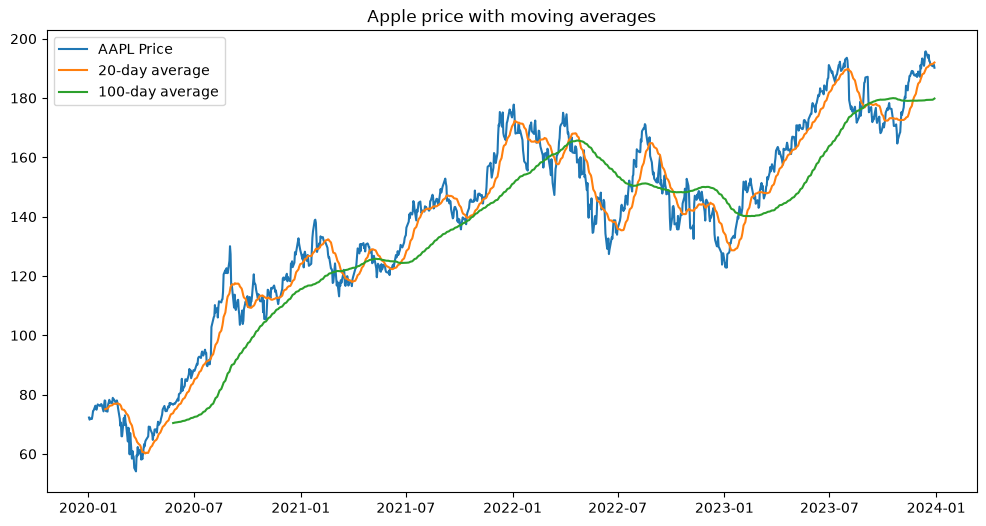

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

data = yf.download("AAPL", start="2020-01-01", end="2024-01-01", auto_adjust=True)
data.columns = data.columns.droplevel(1)

data["SMA_short"] = data["Close"].rolling(20).mean()
data["SMA_long"] = data["Close"].rolling(100).mean()

plt.figure(figsize=(12, 6))
plt.plot(data["Close"], label="AAPL Price")
plt.plot(data["SMA_short"], label="20-day average")
plt.plot(data["SMA_long"], label="100-day average")
plt.legend()
plt.title("Apple price with moving averages")
plt.show()

In [2]:
def get_data(ticker, start="2020-01-01", end="2024-01-01"):
    data = yf.download(ticker, start=start, end=end, auto_adjust=True)
    data.columns = data.columns.droplevel(1)
    data["SMA_short"] = data["Close"].rolling(20).mean()
    data["SMA_long"] = data["Close"].rolling(100).mean()
    return data

aapl = get_data("AAPL")
msft = get_data("MSFT")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


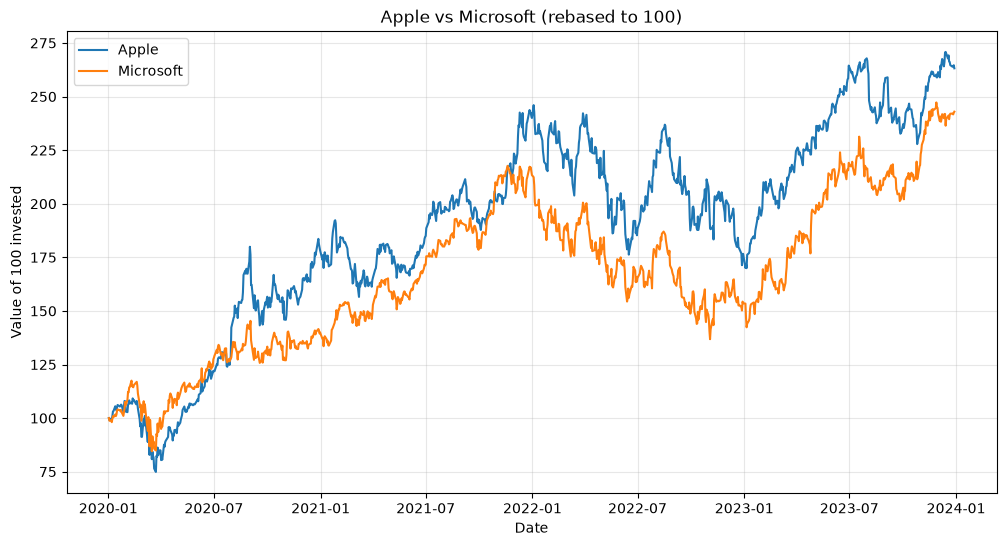

In [3]:
plt.figure(figsize=(12, 6))
plt.plot(aapl["Close"] / aapl["Close"].iloc[0] * 100, label="Apple")
plt.plot(msft["Close"] / msft["Close"].iloc[0] * 100, label="Microsoft")
plt.legend()
plt.title("Apple vs Microsoft (rebased to 100)")
plt.xlabel("Date")
plt.ylabel("Value of 100 invested")
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
aapl_final = aapl["Close"].iloc[-1] / aapl["Close"].iloc[0] * 100
msft_final = msft["Close"].iloc[-1] / msft["Close"].iloc[0] * 100

print(f"Apple: 100 became {aapl_final:.1f} ({aapl_final - 100:.1f}% return)")
print(f"Microsoft: 100 became {msft_final:.1f} ({msft_final - 100:.1f}% return)")

Apple: 100 became 263.2 (163.2% return)
Microsoft: 100 became 243.0 (143.0% return)


In [5]:
def add_strategy(data):
    data["Signal"] = (data["SMA_short"] > data["SMA_long"]).astype(int)
    data["Returns"] = data["Close"].pct_change().fillna(0)
    data["Strategy_Returns"] = data["Signal"].shift(1).fillna(0) * data["Returns"]
    data["BuyHold"] = (1 + data["Returns"]).cumprod() * 100
    data["Strategy"] = (1 + data["Strategy_Returns"]).cumprod() * 100
    return data

aapl = add_strategy(aapl)
msft = add_strategy(msft)

print(f"Apple:     Buy & hold {aapl['BuyHold'].iloc[-1]:.1f} | Strategy {aapl['Strategy'].iloc[-1]:.1f}")
print(f"Microsoft: Buy & hold {msft['BuyHold'].iloc[-1]:.1f} | Strategy {msft['Strategy'].iloc[-1]:.1f}")

Apple:     Buy & hold 263.2 | Strategy 170.7
Microsoft: Buy & hold 243.0 | Strategy 179.7


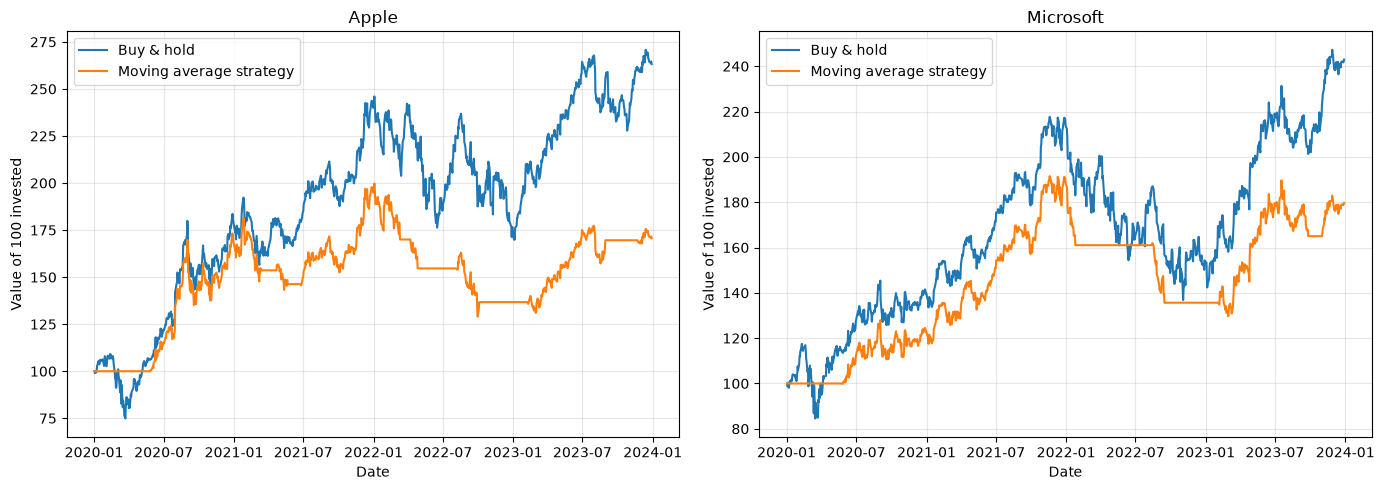

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, df, name in zip(axes, [aapl, msft], ["Apple", "Microsoft"]):
    ax.plot(df["BuyHold"], label="Buy & hold")
    ax.plot(df["Strategy"], label="Moving average strategy")
    ax.set_title(name)
    ax.set_xlabel("Date")
    ax.set_ylabel("Value of 100 invested")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

The moving average strategy returned 75% on Apple and 80% on Microsoft, versus 163% and 143% for buy-and-hold. The strategy lagged because it spent time out of the market during a strong bull run.

In [7]:
import pandas as pd

def metrics(returns):
    cumulative = (1 + returns).cumprod()
    drawdown = cumulative / cumulative.cummax() - 1
    return {
        "Total return (%)": round((cumulative.iloc[-1] - 1) * 100, 1),
        "Max drawdown (%)": round(drawdown.min() * 100, 1),
        "Sharpe ratio": round(returns.mean() / returns.std() * (252 ** 0.5), 2),
    }

results = pd.DataFrame({
    "Apple buy & hold": metrics(aapl["Returns"]),
    "Apple strategy": metrics(aapl["Strategy_Returns"]),
    "Microsoft buy & hold": metrics(msft["Returns"]),
    "Microsoft strategy": metrics(msft["Strategy_Returns"]),
})

results

,Apple buy & hold,Apple strategy,Microsoft buy & hold,Microsoft strategy
Total return (%),163.20,70.7,143.00,79.70
Max drawdown (%),-31.40,-35.4,-37.10,-32.30
Sharpe ratio,0.89,0.7,0.85,0.84


Over 2020-2024, the 20/100-day moving average strategy underperformed buy-and-hold on both stocks. On Apple it returned 70.7% vs 163.2%, with a deeper maximum drawdown (-35.4% vs -31.4%) and a lower Sharpe ratio (0.70 vs 0.89). On Microsoft it returned 79.7% vs 143.0%, with a slightly shallower drawdown (-32.3% vs -37.1%) but a similar Sharpe ratio (0.84 vs 0.85). The strategy did not improve risk-adjusted returns on either stock.

In [8]:
windows = [(10, 50), (20, 100), (50, 200)]

for short, long in windows:
    for name, df in [("Apple", aapl), ("Microsoft", msft)]:
        signal = (df["Close"].rolling(short).mean() > df["Close"].rolling(long).mean()).astype(int)
        strat = signal.shift(1).fillna(0) * df["Returns"]
        total = ((1 + strat).cumprod().iloc[-1] - 1) * 100
        print(f"{name} {short}/{long}: strategy return {total:.1f}%")

Apple 10/50: strategy return 100.8%
Microsoft 10/50: strategy return 41.6%
Apple 20/100: strategy return 70.7%
Microsoft 20/100: strategy return 79.7%
Apple 50/200: strategy return 38.5%
Microsoft 50/200: strategy return 88.7%


I tested three moving average pairs (10/50, 20/100, 50/200) on both stocks. None beat buy-and-hold over 2020-2024. The best-performing window differed between Apple (10/50) and Microsoft (50/200), suggesting no setting is reliably better and results depend on the stock and period. Longer windows were also disadvantaged by a warm-up period spent in cash.

## Conclusion

I tested a moving average crossover strategy on Apple and Microsoft over 2020-2024 and compared it with simply buying and holding.

- **Returns:** The strategy underperformed buy-and-hold on both stocks. With a 20/100-day window, Apple returned 70.7% vs 163.2%, and Microsoft 79.7% vs 143.0%.
- **Risk:** The strategy did not reliably reduce risk. On Apple the maximum drawdown was worse (-35.4% vs -31.4%). On Microsoft it was slightly better (-32.3% vs -37.1%), but the Sharpe ratio was about the same (0.84 vs 0.85).
- **Robustness:** I tested three window pairs (10/50, 20/100, 50/200). None beat buy-and-hold on either stock, and the best window differed between companies, so the results don't point to a reliable setting.

Over this period, which was a strong bull market for large tech stocks, the strategy gave up a lot of return without improving risk-adjusted performance.

## Limitations

- **No transaction costs or slippage.** Real trading costs would lower the strategy's returns further, especially for faster windows that trade more often.
- **Only two stocks and one time period.** 2020-2024 was an unusually strong period for tech, so the results may not hold in other markets, such as a prolonged downturn.
- **Warm-up period.** Longer windows need 100-200 days of data before producing a signal, and the strategy sits in cash during that time. This disadvantages them. Downloading earlier data would make the test fairer.
- **Backtests are not predictions.** Past performance does not show how a strategy will behave in future.
- **Simple strategy.** I tested only one type of signal, with no position sizing or risk management.